# IPN-Hand — Complete VideoMamba P1 Results & 16-Frame Keyframe Explorer

**English-only Kaggle notebook.** Analyze the *saved Notebook Output* of the completed VideoMamba P1 evaluation; **no re-inference, source videos, checkpoint, or GPU required**. Start with **Add Input → Notebook Output** and attach the completed output for **IPN-Hand**. Use **Accelerator: None**.

### Contents
- Full **class-code legend** (e.g. `G06`, `B0A`, and `B0B` for IPN-Hand; `0`–`8` for CTPGesture) with original English class names and zero-based indices.
- Inventory of **all result files**, JSON metrics, and **every CSV** with searchable pagination.
- **All** Isolated and Continuous keyframe cases with Ground Truth, Prediction, correct/error status, temporal boundaries, confidence/tIoU, source, and full row metadata.
- Early Accuracy, Isolated confusion matrix, Continuous per-video metrics, other plots, saved notes, and cache inventory.

**Interpretation:** Continuous case-level errors may represent class confusion, missed gestures, fragmentation, boundary mismatch or false positives. The GT/Pred labels shown for unmatched events can be **midpoint contextual labels**, not a corresponding matched segment. GT-prefix Early Accuracy is **not** Online Early@10 or time-to-command.

**Performance:** The gallery indexes 100% of cases but displays 8 images per page by default. Bulk inline rendering is available as an explicit opt-in in the last cell; it may overload Kaggle/browser memory.

## 1. Connect completed Kaggle Output and display the full class-code reference

In [10]:
from pathlib import Path
import os, json, math, html, base64, warnings
import pandas as pd
import numpy as np
from IPython.display import display, HTML, Markdown, clear_output

DATASET_NAME = 'IPN-Hand'
EXPECTED_ROOT_TOKEN = 'p1_ipn_re_evaluation'
CLASS_CODES = ['D0X', 'B0A', 'B0B', 'G01', 'G02', 'G03', 'G04', 'G05', 'G06', 'G07', 'G08', 'G09', 'G10', 'G11']
CLASS_DESCRIPTIONS = ['No gesture', 'Pointing with one finger', 'Pointing with two fingers', 'Click with one finger', 'Click with two fingers', 'Throw up', 'Throw down', 'Throw left', 'Throw right', 'Open twice', 'Double click with one finger', 'Double click with two fingers', 'Zoom in', 'Zoom out']
assert len(CLASS_CODES) == len(CLASS_DESCRIPTIONS)
CLASS_LABELS = [f'{code} — {name}' for code, name in zip(CLASS_CODES, CLASS_DESCRIPTIONS)]
CLASS_TABLE = pd.DataFrame({
    'Class index (0-based)': list(range(len(CLASS_CODES))),
    'Class code': CLASS_CODES,
    'Class name (English)': CLASS_DESCRIPTIONS,
})
# The attached Notebook Output is read-only. Set this if multiple runs are attached.
OUTPUT_INPUT_PATH = None             # e.g. '/kaggle/input/your-notebook-output'
INPUT_ROOT = Path('/kaggle/input')
SEARCH_ROOT = Path(OUTPUT_INPUT_PATH) if OUTPUT_INPUT_PATH else INPUT_ROOT
if not SEARCH_ROOT.is_dir():
    raise FileNotFoundError('Cannot locate Kaggle Input. Use Add Input > Notebook Output first.')

iso_files = sorted(SEARCH_ROOT.rglob('isolated_all_samples_index.csv'))
cont_files = sorted(SEARCH_ROOT.rglob('continuous_all_events_index.csv'))
iso_by_root = {p.parent.parent.resolve(): p for p in iso_files}
cont_by_root = {p.parent.parent.resolve(): p for p in cont_files}
matching_roots = sorted(
    [root for root in set(iso_by_root) & set(cont_by_root)
     if EXPECTED_ROOT_TOKEN.lower() in str(root).lower()], key=str)
print(f'Detected complete {DATASET_NAME} runs: {len(matching_roots)}')
for root in matching_roots: print('  -', root)
if len(matching_roots) != 1:
    raise RuntimeError('Attach exactly one completed Notebook Output with both image-index CSVs, '
                       'or set OUTPUT_INPUT_PATH to that specific Output directory.')
P1_ROOT = matching_roots[0]
ISO_INDEX_CSV = iso_by_root[P1_ROOT]
CONT_INDEX_CSV = cont_by_root[P1_ROOT]
OUTPUT_ROOT = P1_ROOT.parent
REPORT_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path('/tmp')
REPORT_DIR.mkdir(parents=True,exist_ok=True)
print('\nSelected input:',OUTPUT_ROOT)
print('Isolated index:', ISO_INDEX_CSV.relative_to(OUTPUT_ROOT))
print('Continuous index:', CONT_INDEX_CSV.relative_to(OUTPUT_ROOT))
print('\nCOMPLETE CLASS CODE REFERENCE')
display(CLASS_TABLE)
CLASS_TABLE.to_csv(REPORT_DIR/f'{DATASET_NAME}_class_reference.csv',index=False)
print('Note: B0D is NOT among the 14 class codes used by this IPN-Hand checkpoint. The B-series codes here are B0A and B0B.')

Detected complete IPN-Hand runs: 1
  - /kaggle/input/notebooks/hoanganh94/videomamba-ipn-hand-p1-metrics-keyframes-python313/p1_ipn_re_evaluation

Selected input: /kaggle/input/notebooks/hoanganh94/videomamba-ipn-hand-p1-metrics-keyframes-python313
Isolated index: p1_ipn_re_evaluation/isolated_16frame/isolated_all_samples_index.csv
Continuous index: p1_ipn_re_evaluation/continuous_16frame_timeline/continuous_all_events_index.csv

COMPLETE CLASS CODE REFERENCE


,Class index (0-based),Class code,Class name (English)
0,0,D0X,No gesture
1,1,B0A,Pointing with one finger
2,2,B0B,Pointing with two fingers
3,3,G01,Click with one finger
4,4,G02,Click with two fingers
5,5,G03,Throw up
6,6,G04,Throw down
7,7,G05,Throw left
8,8,G06,Throw right
9,9,G07,Open twice


Note: B0D is NOT among the 14 class codes used by this IPN-Hand checkpoint. The B-series codes here are B0A and B0B.


## 2. Inventory every exported result file

In [11]:
# Complete inventory of relevant exported results; exclude source-code clones.
EXTENSIONS = {'.csv','.json','.jpg','.jpeg','.png','.pkl','.pickle','.parquet','.npz','.npy',
              '.txt','.log','.md','.html','.tsv','.yaml','.yml','.pdf','.svg'}
EXCLUDED_DIRS = {'VideoMamba','.git','__pycache__','.ipynb_checkpoints','site-packages','node_modules'}
FILE_TYPES = {'.csv':'CSV table','.json':'JSON metrics','.jpg':'JPEG keyframe','.jpeg':'JPEG keyframe',
              '.png':'PNG figure','.svg':'SVG figure','.pkl':'Raw inference cache','.pickle':'Raw inference cache',
              '.parquet':'Parquet data','.npz':'NumPy array','.npy':'NumPy array','.txt':'Text file',
              '.log':'Log file','.md':'Markdown file','.html':'HTML report','.tsv':'TSV table',
              '.yaml':'Configuration','.yml':'Configuration','.pdf':'PDF report'}
inventory_rows=[]
for folder, dirs, names in os.walk(OUTPUT_ROOT):
    dirs[:] = [name for name in dirs if name not in EXCLUDED_DIRS]
    for name in names:
        path=Path(folder)/name
        if path.suffix.lower() not in EXTENSIONS: continue
        try: size=path.stat().st_size
        except OSError: size=0
        inventory_rows.append({'Type':FILE_TYPES.get(path.suffix.lower(),'Other'),
            'Filename':path.name,'Relative path':path.relative_to(OUTPUT_ROOT).as_posix(),
            'Size (KiB)':round(size/1024,1),'Absolute path':str(path)})
INVENTORY = pd.DataFrame(inventory_rows,columns=['Type','Filename','Relative path','Size (KiB)','Absolute path'])
INVENTORY = INVENTORY.sort_values(['Type','Relative path']).reset_index(drop=True)
print(f'TOTAL RESULT FILES: {len(INVENTORY):,}')
if len(INVENTORY):
    display(INVENTORY.groupby('Type',as_index=False).agg(
        Files=('Filename','size'),Total_MiB=('Size (KiB)',lambda x:round(x.sum()/1024,2))))
    print('\nALL NON-KEYFRAME RESULT FILES')
    display(INVENTORY[INVENTORY['Type']!='JPEG keyframe'][['Type','Relative path','Size (KiB)']].reset_index(drop=True))
INVENTORY.drop(columns=['Absolute path']).to_csv(REPORT_DIR/f'{DATASET_NAME}_output_inventory.csv',index=False)
print('\nInventory saved:',REPORT_DIR/f'{DATASET_NAME}_output_inventory.csv')

TOTAL RESULT FILES: 2,670


,Type,Files,Total_MiB
0,CSV table,25,5.52
1,HTML report,1,0.80
2,JPEG keyframe,2635,373.36
3,JSON metrics,8,0.04
4,Raw inference cache,1,2.55



ALL NON-KEYFRAME RESULT FILES


,Type,Relative path,Size (KiB)
0,CSV table,p1_ipn_re_evaluation/continuous_16frame_timeli...,723.9
1,CSV table,p1_ipn_re_evaluation/continuous_16frame_timeli...,0.0
2,CSV table,p1_ipn_re_evaluation/continuous_correct_cases.csv,132.4
3,CSV table,p1_ipn_re_evaluation/continuous_error_cases.csv,175.9
4,CSV table,p1_ipn_re_evaluation/continuous_raw_segment_me...,7.8
5,CSV table,p1_ipn_re_evaluation/early_accuracy_curve.csv,0.3
6,CSV table,p1_ipn_re_evaluation/extra_continuous_metrics/...,99.8
7,CSV table,p1_ipn_re_evaluation/extra_continuous_metrics/...,1.0
8,CSV table,p1_ipn_re_evaluation/extra_continuous_metrics/...,11.6
9,CSV table,p1_ipn_re_evaluation/extra_isolated_metrics/ea...,47.5



Inventory saved: /kaggle/working/IPN-Hand_output_inventory.csv


## 3. Full JSON metrics and raw values

In [12]:
# Read every JSON result and preserve all original metric keys and values.
def flatten_json(value, prefix=''):
    if isinstance(value,dict):
        for key,item in value.items():
            yield from flatten_json(item, f'{prefix}.{key}' if prefix else str(key))
    elif isinstance(value,list):
        if len(value)<=50:
            for i,item in enumerate(value): yield from flatten_json(item,f'{prefix}[{i}]')
        else: yield prefix,value
    else: yield prefix,value

JSON_RESULTS={}
metric_rows=[]
for filename in INVENTORY.loc[INVENTORY['Type']=='JSON metrics','Absolute path']:
    path=Path(filename)
    try:
        with path.open('r',encoding='utf-8') as fh: content=json.load(fh)
        relative=path.relative_to(OUTPUT_ROOT).as_posix()
        JSON_RESULTS[relative]=content
        print('\n'+'='*78+'\nJSON FILE:',relative)
        display(HTML('<pre style="white-space:pre-wrap;overflow:auto;max-height:550px;border:1px solid #ddd;padding:10px">'
                     +html.escape(json.dumps(content,ensure_ascii=False,indent=2,default=str))+'</pre>'))
        for name,value in flatten_json(content):
            metric_rows.append({'Source JSON':relative,'Metric key':name,
                'Value':value if isinstance(value,(str,int,float,bool,type(None)))
                else json.dumps(value,ensure_ascii=False,default=str)})
    except Exception as e: print('Could not read JSON:',path.name,'|',e)
METRIC_INDEX=pd.DataFrame(metric_rows,columns=['Source JSON','Metric key','Value'])
print('\nFULL JSON METRIC INDEX')
if len(METRIC_INDEX): display(METRIC_INDEX)
else: print('No JSON metric files detected. The CSV browser below may contain the metrics.')


JSON FILE: __huggingface_repos__.json



JSON FILE: __output__.json



JSON FILE: p1_cuda_runtime_audit.json



JSON FILE: p1_ipn_re_evaluation/continuous_raw_segment_metrics_summary.json



JSON FILE: p1_ipn_re_evaluation/early_auc.json



JSON FILE: p1_ipn_re_evaluation/extra_continuous_metrics/detection_boundary_summary.json



JSON FILE: p1_ipn_re_evaluation/extra_isolated_metrics/early_correctness_summary.json



JSON FILE: p1_ipn_re_evaluation/isolated_calibration.json



FULL JSON METRIC INDEX


,Source JSON,Metric key,Value
0,__output__.json,,"[{""stream_name"": ""stderr"", ""time"": 7.037080626..."
1,p1_cuda_runtime_audit.json,python,3.13.15
2,p1_cuda_runtime_audit.json,torch,2.11.0+cu128
3,p1_cuda_runtime_audit.json,torch_cuda,12.8
4,p1_cuda_runtime_audit.json,gpu,Tesla T4
...,...,...,...
70,p1_ipn_re_evaluation/extra_isolated_metrics/ea...,warning,Offline GT-defined isolated prefixes only; not...
71,p1_ipn_re_evaluation/isolated_calibration.json,n,1101
72,p1_ipn_re_evaluation/isolated_calibration.json,ece_15,0.029848
73,p1_ipn_re_evaluation/isolated_calibration.json,multiclass_brier_sum,0.197447


## 4. Every CSV table: complete columns, previews and searchable pagination

In [13]:
# Every CSV is indexed. Browse any row without dropping data from the source.
CSV_PATHS={str(Path(p).relative_to(OUTPUT_ROOT)):Path(p) for p in
           INVENTORY.loc[INVENTORY['Type']=='CSV table','Absolute path']}
CSV_CACHE={}
def read_table(filename):
    if filename not in CSV_PATHS: raise KeyError(f'CSV not found: {filename}')
    if filename not in CSV_CACHE: CSV_CACHE[filename]=pd.read_csv(CSV_PATHS[filename],low_memory=False)
    return CSV_CACHE[filename]

def annotated_table(dataframe):
    out=dataframe.copy()
    for column in ['gt_idx','pred_idx','class_idx','gt_class','label']:
        if column in out.columns:
            ids=pd.to_numeric(out[column],errors='coerce')
            out[f'{column} / Class name']=ids.map(
                lambda i: CLASS_LABELS[int(i)] if pd.notna(i) and 0<=int(i)<len(CLASS_LABELS) else 'Unknown')
    if 'correct' in out.columns:
        out['Classification result']=out['correct'].map(
            lambda x:'Correct' if str(x).lower() in ('true','1','yes') else 'Incorrect')
    if 'status' in out.columns:
        out['Event result']=out['status'].map({'correct':'Correct','error':'Error'}).fillna('Other')
    return out

def show_csv(filename,page=1,rows_per_page=30,search=''):
    df=read_table(filename)
    if search:
        hit=df.astype(str).apply(lambda col:col.str.contains(search,case=False,regex=False,na=False)).any(axis=1)
        df=df[hit]
    rows_per_page=max(1,int(rows_per_page))
    num_pages=max(1,math.ceil(len(df)/rows_per_page))
    page=max(1,min(int(page),num_pages))
    first=(page-1)*rows_per_page
    print(f'CSV: {filename} | {len(df):,} rows × {len(df.columns)} columns | '
          f'Page {page}/{num_pages} | Rows {first+1 if len(df) else 0}–{min(first+rows_per_page,len(df))}')
    display(annotated_table(df.iloc[first:first+rows_per_page]))
    return num_pages

print('CSV FILES:',len(CSV_PATHS))
for filename in sorted(CSV_PATHS):
    try:
        table=read_table(filename)
        print('\n'+'─'*78+'\n',f'{filename}: {len(table):,} rows, {len(table.columns)} columns')
        print('Original columns:',', '.join(map(str,table.columns)))
        display(annotated_table(table.head(5)))
    except Exception as e: print('Unable to read CSV:',filename,'|',e)

try:
    import ipywidgets as widgets
    if CSV_PATHS:
        csv_choice=widgets.Dropdown(options=sorted(CSV_PATHS),description='CSV:',layout=widgets.Layout(width='98%'))
        csv_page=widgets.BoundedIntText(value=1,min=1,max=999999,description='Page:')
        csv_rows=widgets.Dropdown(options=[10,20,30,50,100,200],value=30,description='Rows:')
        csv_search=widgets.Text(description='Search:',placeholder='Search across all columns')
        csv_prev=widgets.Button(description='Previous page')
        csv_next=widgets.Button(description='Next page')
        csv_output=widgets.Output()
        def update_csv(*_):
            with csv_output:
                clear_output(wait=True)
                pages=show_csv(csv_choice.value,csv_page.value,csv_rows.value,csv_search.value)
            csv_prev.disabled=(csv_page.value<=1)
            csv_next.disabled=(csv_page.value>=pages)
        def reset_csv_page(change):
            if change['name']=='value':
                if csv_page.value!=1: csv_page.value=1
                else:update_csv()
        for w in [csv_choice,csv_rows,csv_search]:w.observe(reset_csv_page,names='value')
        csv_page.observe(lambda c:update_csv() if c['name']=='value' else None,names='value')
        csv_prev.on_click(lambda _:setattr(csv_page,'value',max(1,csv_page.value-1)))
        csv_next.on_click(lambda _:setattr(csv_page,'value',csv_page.value+1))
        display(widgets.VBox([csv_choice,widgets.HBox([csv_page,csv_rows,csv_prev,csv_next]),csv_search,csv_output]))
        update_csv()
except Exception as exc:
    print('Interactive CSV browser unavailable:',exc)
    print('Manual example: show_csv(next(iter(CSV_PATHS)),page=1,rows_per_page=30)')

CSV FILES: 25

──────────────────────────────────────────────────────────────────────────────
 p1_ipn_re_evaluation/continuous_16frame_timeline/continuous_all_events_index.csv: 1,526 rows, 22 columns
Original columns: video, status, kind, source, start, end, gt_idx, pred_idx, tiou, representative_window_index, window_start, window_end, model_input_indices_zero_based, contributing_windows_at_midpoint, contributing_windows_over_event, number_of_contributing_windows_at_midpoint, number_of_contributing_windows_over_event, video_path, image_path, duration_sec, sampled_frames, protocol


,video,status,kind,source,start,end,gt_idx,pred_idx,tiou,representative_window_index,...,number_of_contributing_windows_at_midpoint,number_of_contributing_windows_over_event,video_path,image_path,duration_sec,sampled_frames,protocol,gt_idx / Class name,pred_idx / Class name,Event result
0,1CM1_1_R__217.avi,error,duplicate_or_fragmented_prediction,unmatched_prediction,0,95,12,12,0.458333,1,...,3,6,/kaggle/input/datasets/soumicksarker/ipn-hand-...,/kaggle/working/p1_ipn_re_evaluation/continuou...,3.200000,16,RAW offline overlapping-window aggregation,G10 — Zoom in,G10 — Zoom in,Error
1,1CM1_1_R__217.avi,error,boundary_or_fragmentation,ground_truth,28,71,12,12,0.458333,1,...,4,5,/kaggle/input/datasets/soumicksarker/ipn-hand-...,/kaggle/working/p1_ipn_re_evaluation/continuou...,1.466667,16,RAW offline overlapping-window aggregation,G10 — Zoom in,G10 — Zoom in,Error
2,1CM1_1_R__217.avi,correct,matched_gt_gesture_tiou_ge_050,ground_truth,72,234,1,1,0.785276,8,...,4,14,/kaggle/input/datasets/soumicksarker/ipn-hand-...,/kaggle/working/p1_ipn_re_evaluation/continuou...,5.433333,16,RAW offline overlapping-window aggregation,B0A — Pointing with one finger,B0A — Pointing with one finger,Correct
3,1CM1_1_R__217.avi,error,duplicate_or_fragmented_prediction,unmatched_prediction,224,287,9,9,0.390625,14,...,4,7,/kaggle/input/datasets/soumicksarker/ipn-hand-...,/kaggle/working/p1_ipn_re_evaluation/continuou...,2.133333,16,RAW offline overlapping-window aggregation,G07 — Open twice,G07 — Open twice,Error
4,1CM1_1_R__217.avi,error,boundary_or_fragmentation,ground_truth,235,259,9,9,0.390625,13,...,4,6,/kaggle/input/datasets/soumicksarker/ipn-hand-...,/kaggle/working/p1_ipn_re_evaluation/continuou...,0.833333,16,RAW offline overlapping-window aggregation,G07 — Open twice,G07 — Open twice,Error


Unable to read CSV: p1_ipn_re_evaluation/continuous_16frame_timeline/continuous_export_failures.csv | No columns to parse from file

──────────────────────────────────────────────────────────────────────────────
 p1_ipn_re_evaluation/continuous_correct_cases.csv: 964 rows, 9 columns
Original columns: video, video_path, start, end, indexing, gt_idx, pred_idx, duration_frames, correct


,video,video_path,start,end,indexing,gt_idx,pred_idx,duration_frames,correct,gt_idx / Class name,pred_idx / Class name,Classification result
0,1CM1_3_R__227.avi,/kaggle/input/datasets/soumicksarker/ipn-hand-...,3682,4362,IPN_1_based,2,2,681,True,B0B — Pointing with two fingers,B0B — Pointing with two fingers,Correct
1,1CM1_3_R__227.avi,/kaggle/input/datasets/soumicksarker/ipn-hand-...,1921,2413,IPN_1_based,1,1,493,True,B0A — Pointing with one finger,B0A — Pointing with one finger,Correct
2,1CM1_3_R__226.avi,/kaggle/input/datasets/soumicksarker/ipn-hand-...,1537,1991,IPN_1_based,1,1,455,True,B0A — Pointing with one finger,B0A — Pointing with one finger,Correct
3,1CM42_30_R__148.avi,/kaggle/input/datasets/soumicksarker/ipn-hand-...,3185,3632,IPN_1_based,9,9,448,True,G07 — Open twice,G07 — Open twice,Correct
4,1CM42_15_R__198.avi,/kaggle/input/datasets/soumicksarker/ipn-hand-...,417,816,IPN_1_based,1,1,400,True,B0A — Pointing with one finger,B0A — Pointing with one finger,Correct



──────────────────────────────────────────────────────────────────────────────
 p1_ipn_re_evaluation/continuous_error_cases.csv: 1,280 rows, 9 columns
Original columns: video, video_path, start, end, indexing, gt_idx, pred_idx, duration_frames, correct


...

,video,frames,fps,duration_sec,windows,overlap_percent,raw_frame_accuracy,raw_temporal_overlap,final_frame_accuracy,final_temporal_overlap,final_gesture_segments,link_operations,removal_changes,inference_sec,mean_ms_per_window
0,1CM1_1_R__217.avi,3987,30.0,132.900000,247,75.0,0.587911,0.045687,0.607976,0.058741,18,1,8,66.114653,267.670658
1,1CM1_1_R__218.avi,3784,30.0,126.133333,234,75.0,0.512949,0.000000,0.542548,0.023124,16,2,6,62.902714,268.815018
2,1CM1_1_R__219.avi,3921,30.0,130.700000,243,75.0,0.630196,0.114892,0.646519,0.211224,23,4,4,64.534111,265.572472
3,1CM1_1_R__220.avi,3889,30.0,129.633333,241,75.0,0.743379,0.201448,0.749036,0.212852,21,1,5,64.476584,267.537694
4,1CM1_2_R__221.avi,3796,30.0,126.533333,235,75.0,0.804268,0.497396,0.784510,0.432182,15,0,6,64.422889,274.139953



──────────────────────────────────────────────────────────────────────────────
 videomamba_ipn_continuous_summary.csv: 7 rows, 2 columns
Original columns: Metric, Value


,Metric,Value
0,Videos,52.000000
1,Mean per-video raw Frame Accuracy,0.834889
2,Mean per-video final Frame Accuracy,0.834946
3,Global raw Frame Accuracy,0.837308
4,Global final Frame Accuracy,0.837341



──────────────────────────────────────────────────────────────────────────────
 videomamba_ipn_isolated_test.csv: 1,101 rows, 26 columns
Original columns: video, video_path, t_start, t_end, duration_frames, gt_idx, gt_code, pred_idx, pred_code, confidence, correct, prob_0, prob_1, prob_2, prob_3, prob_4, prob_5, prob_6, prob_7, prob_8, prob_9, prob_10, prob_11, prob_12, prob_13, sampled_frame_indices


,video,video_path,t_start,t_end,duration_frames,gt_idx,gt_code,pred_idx,pred_code,confidence,...,prob_8,prob_9,prob_10,prob_11,prob_12,prob_13,sampled_frame_indices,gt_idx / Class name,pred_idx / Class name,Classification result
0,1CM1_1_R__217,/kaggle/input/datasets/soumicksarker/ipn-hand-...,29,72,44,12,G10,12,G10,0.970943,...,0.001791,0.004093,0.000223,0.000400,0.970943,0.020030,"29,32,35,38,40,43,46,49,52,55,58,61,63,66,69,72",G10 — Zoom in,G10 — Zoom in,Correct
1,1CM1_1_R__217,/kaggle/input/datasets/soumicksarker/ipn-hand-...,73,235,163,1,B0A,1,B0A,0.561081,...,0.001661,0.002438,0.150696,0.001035,0.003538,0.004840,"73,84,95,105,116,127,138,149,159,170,181,192,2...",B0A — Pointing with one finger,B0A — Pointing with one finger,Correct
2,1CM1_1_R__217,/kaggle/input/datasets/soumicksarker/ipn-hand-...,236,260,25,9,G07,3,G01,0.619407,...,0.000315,0.001586,0.360856,0.001947,0.002121,0.001242,"236,238,239,241,242,244,246,247,249,250,252,25...",G07 — Open twice,G01 — Click with one finger,Incorrect
3,1CM1_1_R__217,/kaggle/input/datasets/soumicksarker/ipn-hand-...,261,448,188,1,B0A,1,B0A,0.849998,...,0.004245,0.031234,0.029505,0.000334,0.003680,0.004624,"261,273,286,298,311,323,336,348,361,373,386,39...",B0A — Pointing with one finger,B0A — Pointing with one finger,Correct
4,1CM1_1_R__217,/kaggle/input/datasets/soumicksarker/ipn-hand-...,449,509,61,13,G11,1,B0A,0.907433,...,0.000669,0.000579,0.032314,0.000504,0.000571,0.000683,"449,453,457,461,465,469,473,477,481,485,489,49...",G11 — Zoom out,B0A — Pointing with one finger,Incorrect


## 5. Index 100% of Isolated and Continuous cases; restore JPEG paths

In [14]:
# Re-map absolute /kaggle/working paths in old CSVs to attached Notebook Output paths.
iso_data=pd.read_csv(ISO_INDEX_CSV,low_memory=False)
cont_data=pd.read_csv(CONT_INDEX_CSV,low_memory=False)
required_iso={'gt_idx','pred_idx','correct','image_path'}
required_cont={'gt_idx','pred_idx','status','kind','image_path'}
for table,required,group in [(iso_data,required_iso,'Isolated'),(cont_data,required_cont,'Continuous')]:
    if not required.issubset(table.columns):
        raise ValueError(f'{group} index is missing columns: {sorted(required-set(table.columns))}')

def is_true(v): return str(v).strip().lower() in ('true','1','yes')
def class_label(value):
    try:
        i=int(value)
        return CLASS_LABELS[i] if 0<=i<len(CLASS_LABELS) else f'Unknown class index: {i}'
    except Exception: return 'Not available'
def locate_image(csv_folder,raw_path,status):
    basename=Path(str(raw_path)).name
    for candidate in (csv_folder/status/basename,csv_folder/basename):
        if candidate.is_file(): return candidate
    return None

def clean_value(value):
    try: return None if pd.isna(value) else value
    except Exception: return value

cases=[]
for ix,row in iso_data.iterrows():
    gt,pr=int(row['gt_idx']),int(row['pred_idx'])
    status='correct' if is_true(row['correct']) else 'error'
    cases.append({'Protocol':'Isolated','Result':'Correct' if status=='correct' else 'Error',
        'Ground truth':class_label(gt),'Prediction':class_label(pr),
        'GT index':gt,'Pred index':pr,'Video':Path(str(row.get('video_path',''))).name,
        'Sample ID':str(row.get('sample_id',row.get('sample_number',ix+1))),
        'Start frame':clean_value(row.get('original_start',row.get('t_start',np.nan))),
        'End frame':clean_value(row.get('original_end',row.get('t_end',np.nan))),
        'Confidence':clean_value(row.get('confidence',np.nan)),'tIoU':None,
        'Event source':'isolated','Error type':'class_confusion' if status=='error' else 'correct',
        'Image path':locate_image(ISO_INDEX_CSV.parent,row['image_path'],status),
        'Original CSV metadata':row.to_dict()})
for ix,row in cont_data.iterrows():
    gt,pr=int(row['gt_idx']),int(row['pred_idx'])
    status=str(row['status']).lower().strip()
    if status not in ('correct','error'): raise ValueError('Unexpected Continuous status: '+status)
    cases.append({'Protocol':'Continuous','Result':'Correct' if status=='correct' else 'Error',
        'Ground truth':class_label(gt),'Prediction':class_label(pr),
        'GT index':gt,'Pred index':pr,'Video':str(row.get('video',row.get('video_id',''))),
        'Sample ID':Path(str(row['image_path'])).stem,
        'Start frame':clean_value(row.get('start',np.nan)),
        'End frame':clean_value(row.get('end',np.nan)),
        'Confidence':None,'tIoU':clean_value(row.get('tiou',np.nan)),
        'Event source':str(row.get('source','')),'Error type':str(row.get('kind','')),
        'Image path':locate_image(CONT_INDEX_CSV.parent,row['image_path'],status),
        'Original CSV metadata':row.to_dict()})
IMAGE_INDEX=pd.DataFrame(cases)
IMAGE_INDEX=IMAGE_INDEX.sort_values(['Protocol','Result'],ascending=[True,False],kind='stable').reset_index(drop=True)
IMAGE_INDEX['Image found']=IMAGE_INDEX['Image path'].apply(lambda p:p is not None)
IMAGE_INDEX['Search text']=IMAGE_INDEX.apply(lambda row:' '.join(str(row[k]) for k in
    ['Ground truth','Prediction','Video','Sample ID','Error type','Event source']).lower(),axis=1)
print('COMPLETE IMAGE COVERAGE SUMMARY')
display(IMAGE_INDEX.groupby(['Protocol','Result'],as_index=False).agg(
    Cases=('Ground truth','size'),Images_found=('Image found','sum')))
print(f'Total indexed cases: {len(IMAGE_INDEX):,}; accessible JPEGs: {IMAGE_INDEX["Image found"].sum():,}')
if not IMAGE_INDEX['Image found'].all():
    print('WARNING: Some images are missing from the attached Output:')
    display(IMAGE_INDEX[~IMAGE_INDEX['Image found']][['Protocol','Sample ID','Video','Result']].head(50))
    raise FileNotFoundError('Attach a completed Kaggle Notebook Output containing all images and index CSVs.')

COMPLETE IMAGE COVERAGE SUMMARY


,Protocol,Result,Cases,Images_found
0,Continuous,Correct,820,820
1,Continuous,Error,706,706
2,Isolated,Correct,932,932
3,Isolated,Error,169,169


Total indexed cases: 2,627; accessible JPEGs: 2,627


## 6. Complete 16-frame keyframe gallery: Ground Truth vs Prediction, filters and metadata

In [15]:
ERROR_EXPLANATIONS={
    'correct':'Correctly recognized',
    'class_confusion':'Incorrect class',
    'matched_gt_gesture_tiou_ge_050':'Matched GT/predicted segment (tIoU >= 0.50)',
    'boundary_or_fragmentation':'Boundary error or fragmented segment',
    'gesture_class_confusion':'Gesture class confusion',
    'missed_gesture':'Missed ground-truth gesture',
    'duplicate_or_fragmented_prediction':'Duplicate/fragmented prediction',
    'class_confusion_prediction':'Predicted segment has an incorrect class',
    'false_positive_gesture':'False positive (no matching GT segment)',
}
GALLERY_CSS="""<style>
.vm-card{font-family:Arial,sans-serif;color:#202735;max-width:1080px;margin:12px auto 20px;border:1px solid #cbd5e1;border-radius:9px;overflow:hidden}
.vm-head{background:#eff3f8;padding:11px 14px;font-weight:700}
.vm-labels{display:grid;grid-template-columns:1fr 1fr;gap:9px;padding:11px}
.vm-label{background:#f8fafc;padding:11px;border-left:4px solid #2563eb;overflow-wrap:anywhere}
.vm-label.pred{border-left-color:#d97706}
.vm-label small{display:block;color:#52525b;margin-bottom:6px}
.vm-img{display:block;width:100%;height:auto;background:#fff}
.vm-info{padding:10px 12px;font-size:13px;line-height:1.7;overflow-wrap:anywhere}
.vm-note{padding:10px 12px;background:#fffbeb;font-size:12px}
.vm-detail{padding:10px 12px;background:#f8fafc;font-size:12px}
.vm-detail pre{max-height:280px;overflow:auto;white-space:pre-wrap}
</style>"""
def h(value):return html.escape(str(value),quote=True)
def fmt(value):
    try:return 'N/A' if value is None or pd.isna(value) else f'{float(value):.4f}'
    except Exception:return 'N/A'

def filter_images(protocol='All',result='Error',ground_truth='All',prediction='All',video='All',search=''):
    df=IMAGE_INDEX
    for key,choice in [('Protocol',protocol),('Result',result),('Ground truth',ground_truth),
                       ('Prediction',prediction),('Video',video)]:
        if choice!='All': df=df[df[key].eq(choice)]
    if search.strip():df=df[df['Search text'].str.contains(search.lower().strip(),regex=False,na=False)]
    return df

def image_card(row):
    jpg=base64.b64encode(Path(row['Image path']).read_bytes()).decode('ascii')
    if row['Protocol']=='Continuous':
        if row['Event source']=='unmatched_prediction':
            note=('Unmatched predicted segment. The GT label is sampled at its midpoint; '
                  'it does NOT imply that a corresponding ground-truth segment exists.')
        elif row['Result']=='Error':
            note=('Unmatched ground-truth event. The predicted label shown is contextual at the event midpoint; '
                  'the error may be a class confusion, miss, boundary mismatch, or fragmentation.')
        else:
            note='A ground-truth gesture was matched to a same-class prediction at tIoU >= 0.50.'
    else:note='Isolated classification over an annotation-defined gesture interval.'
    metadata=json.dumps(row['Original CSV metadata'],ensure_ascii=False,indent=2,default=str)
    return f"""<article class="vm-card">
      <div class="vm-head">{h(row['Protocol'])} · Sample: {h(row['Sample ID'])} · {h(row['Result']).upper()}</div>
      <div class="vm-labels"><div class="vm-label"><small>GROUND TRUTH</small><b>{h(row['Ground truth'])}</b></div>
      <div class="vm-label pred"><small>MODEL PREDICTION</small><b>{h(row['Prediction'])}</b></div></div>
      <img class="vm-img" loading="lazy" src="data:image/jpeg;base64,{jpg}" alt="Sixteen model-input frames for {h(row['Sample ID'])}"/>
      <div class="vm-info">Video: {h(row['Video'])} · Frames: {h(row['Start frame'])}–{h(row['End frame'])}
      · Confidence: {fmt(row['Confidence'])} · tIoU: {fmt(row['tIoU'])}<br/>
      <strong>Case type:</strong> {h(ERROR_EXPLANATIONS.get(row['Error type'],row['Error type']))}
      · Source: {h(row['Event source'])}</div>
      <div class="vm-note">{h(note)}</div>
      <details class="vm-detail"><summary><b>Show ALL original CSV metadata for this case</b></summary>
      <pre>{h(metadata)}</pre></details></article>"""

def show_images(protocol='All',result='Error',page=1,images_per_page=8,
                ground_truth='All',prediction='All',video='All',search=''):
    df=filter_images(protocol,result,ground_truth,prediction,video,search)
    size=max(1,min(40,int(images_per_page)))
    pages=max(1,math.ceil(len(df)/size));page=max(1,min(int(page),pages))
    start=(page-1)*size
    print(f'Matched images: {len(df):,} | Page {page}/{pages} | Showing '
          f'{start+1 if len(df) else 0}–{min(len(df),start+size)}')
    content=''.join(image_card(row) for _,row in df.iloc[start:start+size].iterrows())
    display(HTML(GALLERY_CSS+(content or '<p>No matching cases.</p>')))
    return pages

print('ISOLATED GROUND TRUTH -> PREDICTION CONFUSIONS')
errors=IMAGE_INDEX[(IMAGE_INDEX['Protocol']=='Isolated')&(IMAGE_INDEX['Result']=='Error')]
if len(errors):
    display(errors.groupby(['Ground truth','Prediction'],as_index=False).size()
            .rename(columns={'size':'Cases'}).sort_values('Cases',ascending=False))
else: print('No isolated classification errors.')
print('\nCONTINUOUS ERROR CATEGORIES')
cont_errors=IMAGE_INDEX[(IMAGE_INDEX['Protocol']=='Continuous')&(IMAGE_INDEX['Result']=='Error')]
if len(cont_errors):
    counts=cont_errors.groupby(['Error type','Event source'],as_index=False).size()
    counts['Description']=counts['Error type'].map(ERROR_EXPLANATIONS).fillna(counts['Error type'])
    display(counts.rename(columns={'size':'Cases'}))

# All cases are indexed; page size is limited solely for browser responsiveness.
try:
    import ipywidgets as widgets
    protocol_w=widgets.Dropdown(options=['All','Isolated','Continuous'],description='Protocol:')
    result_w=widgets.Dropdown(options=['Error','Correct','All'],value='Error',description='Result:')
    gt_w=widgets.Dropdown(options=['All']+CLASS_LABELS,description='GT class:',layout=widgets.Layout(width='460px'))
    pred_w=widgets.Dropdown(options=['All']+CLASS_LABELS,description='Pred class:',layout=widgets.Layout(width='460px'))
    video_w=widgets.Dropdown(options=['All']+sorted(IMAGE_INDEX['Video'].dropna().astype(str).unique().tolist()),
                             description='Video:',layout=widgets.Layout(width='420px'))
    search_w=widgets.Text(description='Search:',placeholder='Class code, video, sample or error type...',
                          layout=widgets.Layout(width='460px'))
    gallery_page=widgets.BoundedIntText(value=1,min=1,max=999999,description='Page:')
    gallery_size=widgets.Dropdown(options=[4,8,12,24,40],value=8,description='Per page:')
    previous_w=widgets.Button(description='Previous')
    next_w=widgets.Button(description='Next')
    info_w=widgets.HTML()
    gallery_output=widgets.Output()
    def update_gallery(*_):
        df=filter_images(protocol_w.value,result_w.value,gt_w.value,pred_w.value,video_w.value,search_w.value)
        pages=max(1,math.ceil(len(df)/gallery_size.value))
        if gallery_page.value>pages:gallery_page.value=pages;return
        with gallery_output:
            clear_output(wait=True)
            show_images(protocol_w.value,result_w.value,gallery_page.value,gallery_size.value,
                        gt_w.value,pred_w.value,video_w.value,search_w.value)
        info_w.value=f'<b>{len(df):,} images · Page {gallery_page.value}/{pages}</b>'
        previous_w.disabled=(gallery_page.value<=1)
        next_w.disabled=(gallery_page.value>=pages)
    def filter_changed(change):
        if change['name']=='value':
            if gallery_page.value!=1:gallery_page.value=1
            else:update_gallery()
    for w in [protocol_w,result_w,gt_w,pred_w,video_w,search_w,gallery_size]:
        w.observe(filter_changed,names='value')
    gallery_page.observe(lambda c:update_gallery() if c['name']=='value' else None,names='value')
    previous_w.on_click(lambda _:setattr(gallery_page,'value',max(1,gallery_page.value-1)))
    next_w.on_click(lambda _:setattr(gallery_page,'value',gallery_page.value+1))
    display(widgets.VBox([widgets.HBox([protocol_w,result_w,gallery_size]),
        widgets.HBox([gt_w,pred_w]),widgets.HBox([video_w,search_w]),
        widgets.HBox([previous_w,gallery_page,next_w,info_w]),gallery_output]))
    update_gallery()
except Exception as exc:
    print('Interactive gallery unavailable:',exc)
    print("Manual: show_images(protocol='All',result='Error',page=1,images_per_page=8)")
    show_images(result='Error',page=1,images_per_page=8)

ISOLATED GROUND TRUTH -> PREDICTION CONFUSIONS


,Ground truth,Prediction,Cases
12,G02 — Click with two fingers,G09 — Double click with two fingers,31
9,G01 — Click with one finger,G08 — Double click with one finger,23
35,G08 — Double click with one finger,G01 — Click with one finger,16
37,G09 — Double click with two fingers,B0B — Pointing with two fingers,9
33,G08 — Double click with one finger,B0A — Pointing with one finger,8
8,G01 — Click with one finger,B0A — Pointing with one finger,7
38,G09 — Double click with two fingers,G02 — Click with two fingers,7
1,B0A — Pointing with one finger,G01 — Click with one finger,6
43,G11 — Zoom out,G10 — Zoom in,5
22,G05 — Throw left,D0X — No gesture,4



CONTINUOUS ERROR CATEGORIES


,Error type,Event source,Cases,Description
0,boundary_or_fragmentation,ground_truth,130,Boundary error or fragmented segment
1,class_confusion_prediction,unmatched_prediction,248,Predicted segment has an incorrect class
2,duplicate_or_fragmented_prediction,unmatched_prediction,139,Duplicate/fragmented prediction
3,false_positive_gesture,unmatched_prediction,38,False positive (no matching GT segment)
4,gesture_class_confusion,ground_truth,131,Gesture class confusion
5,missed_gesture,ground_truth,20,Missed ground-truth gesture


## 7. Graphs from saved metrics and predictions

PLOTS FROM ATTACHED EVALUATION OUTPUT


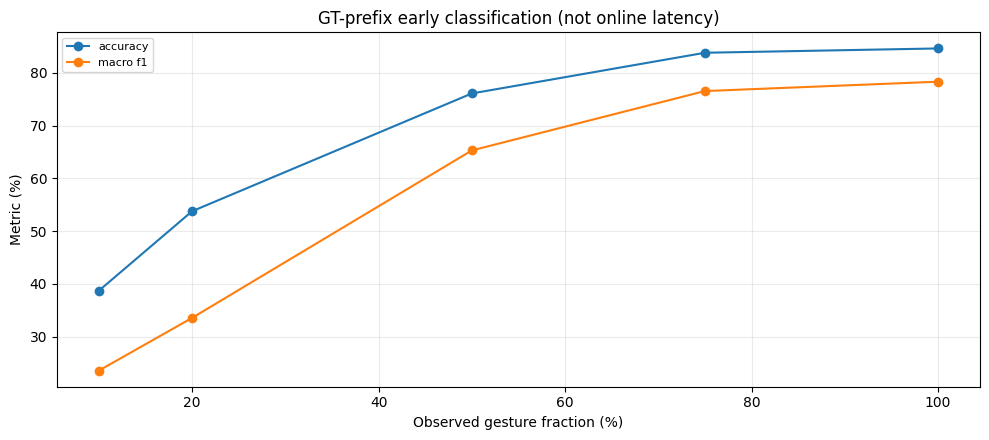

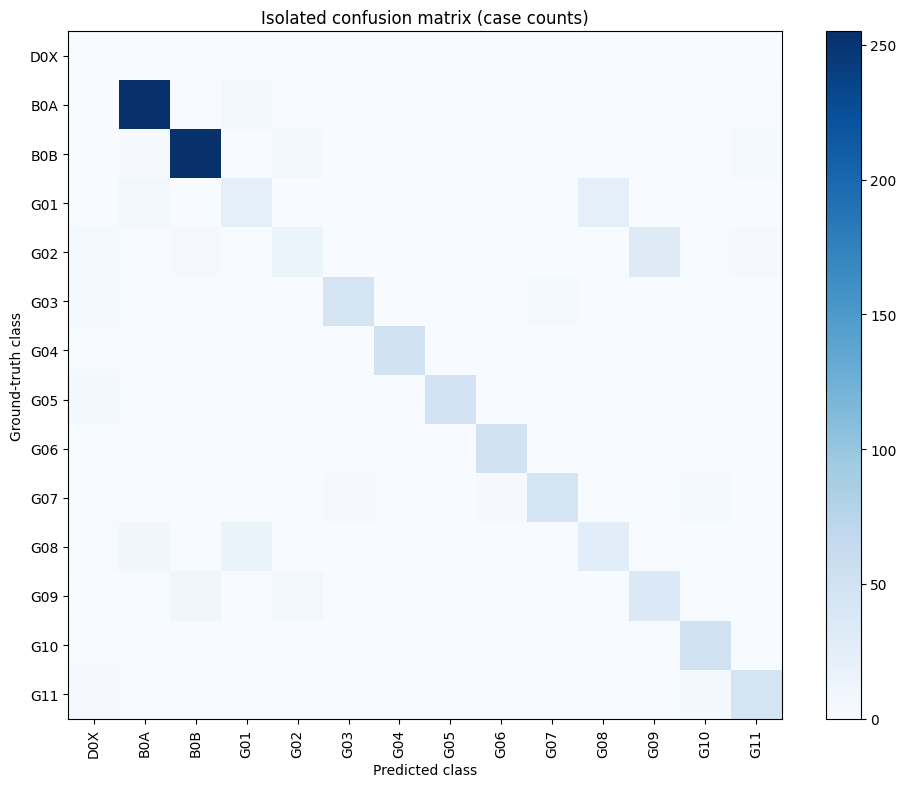

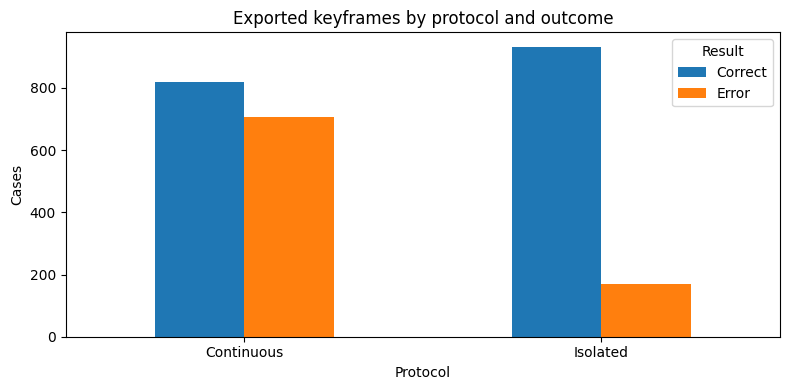

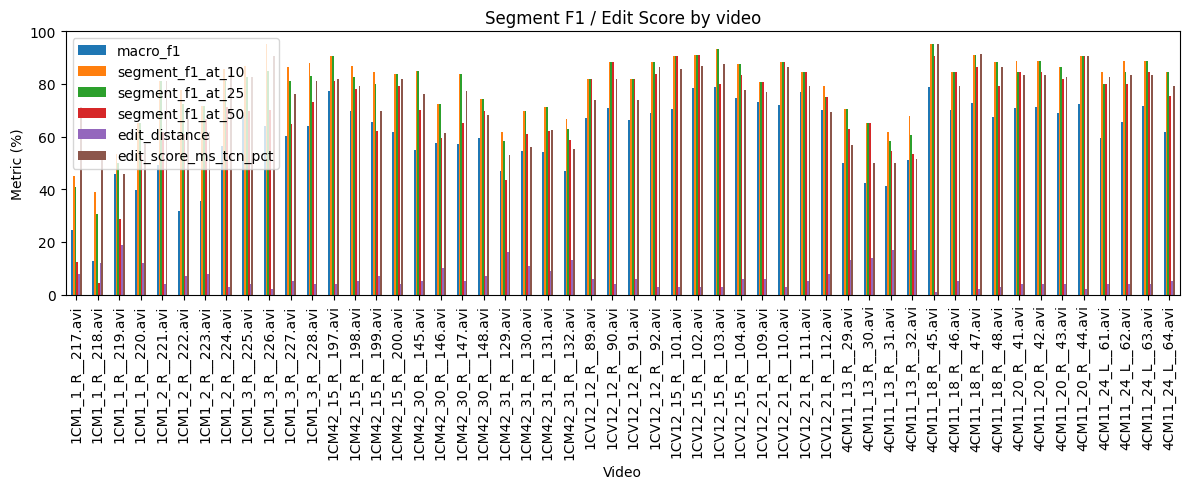

In [16]:
# Plot metrics derived from existing CSVs; no new VideoMamba inference.
import matplotlib.pyplot as plt

def csv_by_basename(filename):
    matches=[name for name in CSV_PATHS if Path(name).name==filename]
    return read_table(matches[0]) if len(matches)==1 else None

print('PLOTS FROM ATTACHED EVALUATION OUTPUT')
# Early Accuracy: annotation-defined prefixes, NOT online prediction latency.
early=csv_by_basename('early_accuracy_curve.csv')
if early is not None:
    xcol=next((c for c in ['observation_ratio','observed_fraction','prefix_ratio'] if c in early),None)
    if xcol:
        ycols=[c for c in early if c!=xcol and ('accuracy' in c.lower() or 'macro_f1' in c.lower())
               and pd.api.types.is_numeric_dtype(early[c])]
        if ycols:
            fig,ax=plt.subplots(figsize=(10,4.5))
            for col in ycols:
                y=pd.to_numeric(early[col],errors='coerce')
                if y.max()<=1.1:y=y*100
                ax.plot(pd.to_numeric(early[xcol])*100,y,marker='o',label=col.replace('_',' '))
            ax.set(xlabel='Observed gesture fraction (%)',ylabel='Metric (%)',
                   title='GT-prefix early classification (not online latency)')
            ax.legend(fontsize=8);ax.grid(alpha=.25);plt.tight_layout();plt.show()
    else: print('The early-curve CSV uses an unrecognized x-axis; inspect it in the CSV browser.')
else: print('No early_accuracy_curve.csv found.')

if {'gt_idx','pred_idx'}.issubset(iso_data.columns):
    truth=iso_data['gt_idx'].astype(int);pred=iso_data['pred_idx'].astype(int)
    confusion=pd.crosstab(truth,pred).reindex(index=range(len(CLASS_CODES)),columns=range(len(CLASS_CODES)),fill_value=0)
    fig,ax=plt.subplots(figsize=(max(9,len(CLASS_CODES)*.7),max(5,len(CLASS_CODES)*.57)))
    view=ax.imshow(confusion.to_numpy(),cmap='Blues',aspect='auto')
    ax.set_xticks(range(len(CLASS_CODES)),labels=CLASS_CODES,rotation=90)
    ax.set_yticks(range(len(CLASS_CODES)),labels=CLASS_CODES)
    ax.set(xlabel='Predicted class',ylabel='Ground-truth class',title='Isolated confusion matrix (case counts)')
    fig.colorbar(view,ax=ax);plt.tight_layout();plt.show()

counts=pd.crosstab(IMAGE_INDEX['Protocol'],IMAGE_INDEX['Result'])
if len(counts):
    ax=counts.plot(kind='bar',figsize=(8,4),rot=0,title='Exported keyframes by protocol and outcome')
    ax.set(xlabel='Protocol',ylabel='Cases');plt.tight_layout();plt.show()

by_video=csv_by_basename('continuous_raw_segment_metrics_per_video.csv')
if by_video is not None and len(by_video):
    cols=[c for c in by_video if 'f1' in c.lower() or 'edit' in c.lower()]
    xcol=next((c for c in ['video_id','video','video_key'] if c in by_video),None)
    if cols and xcol:
        part=by_video[[xcol]+cols].copy().set_index(xcol)
        for col in cols:
            part[col]=pd.to_numeric(part[col],errors='coerce')
            if part[col].max()<=1.1:part[col]*=100
        ax=part.plot(kind='bar',figsize=(12,5),title='Segment F1 / Edit Score by video')
        ax.set(xlabel='Video',ylabel='Metric (%)');plt.tight_layout();plt.show()

## 8. Other figures, logs, notes, artifacts and cache files

In [17]:
# Examine all remaining figures, logs, notes, and cache file metadata.
from IPython.display import Image as NotebookImage
other_images=[Path(x) for x in INVENTORY.loc[INVENTORY['Type']=='PNG figure','Absolute path']]
if not other_images: print('No separate PNG figures found; plots above were reconstructed from saved CSVs.')
for path in other_images:
    print('FIGURE:',path.relative_to(OUTPUT_ROOT))
    display(NotebookImage(filename=str(path),width=900))

text_types={'Text file','Log file','Markdown file','Configuration','TSV table','HTML report'}
text_files=INVENTORY[INVENTORY['Type'].isin(text_types)]
print('\nTEXT FILES / NOTES / LOGS / CONFIGURATION')
if text_files.empty:print('No additional text/configuration files in this Output.')
else:
    for filename in text_files['Absolute path']:
        p=Path(filename)
        try:
            if p.stat().st_size>2_000_000:
                print('Large text file (listed, not embedded):',p.relative_to(OUTPUT_ROOT))
                continue
            contents=p.read_text(encoding='utf-8',errors='replace')
            print('TEXT:',p.relative_to(OUTPUT_ROOT),f'({len(contents):,} characters)')
            display(HTML('<pre style="white-space:pre-wrap;max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
                         +html.escape(contents)+'</pre>'))
        except Exception as e:print('Unable to read text:',p.name,e)

print('\nRAW INFERENCE CACHE / DATA ARRAY / BINARY ARTIFACTS')
cache_types={'Raw inference cache','NumPy array','Parquet data','PDF report','SVG figure'}
cache_files=INVENTORY[INVENTORY['Type'].isin(cache_types)]
if len(cache_files):
    display(cache_files[['Type','Relative path','Size (KiB)']])
    print('Pickle files are intentionally NOT unpickled: deserialization can execute code. '
          'CSV and JSON are displayed above; raw caches are available for controlled offline analysis.')
else:print('No binary or cache files detected.')
print('\nNote: This viewer reads saved results only. It does not recompute predictions or metrics.')

No separate PNG figures found; plots above were reconstructed from saved CSVs.

TEXT FILES / NOTES / LOGS / CONFIGURATION
TEXT: __results__.html (840,081 characters)



RAW INFERENCE CACHE / DATA ARRAY / BINARY ARTIFACTS


,Type,Relative path,Size (KiB)
2669,Raw inference cache,videomamba_postprocess_raw_cache.pkl,2613.9


Pickle files are intentionally NOT unpickled: deserialization can execute code. CSV and JSON are displayed above; raw caches are available for controlled offline analysis.

Note: This viewer reads saved results only. It does not recompute predictions or metrics.


## 9. Optional: embed ALL keyframe images into notebook cell output

In [18]:
# Optional: embed every single JPEG in notebook cell output.
# CAUTION: Thousands of embedded base64 images can make Kaggle or the browser unresponsive.
DISPLAY_ALL_IMAGES_INLINE = False
IMAGES_PER_BATCH = 12
if DISPLAY_ALL_IMAGES_INLINE:
    for protocol in ['Isolated','Continuous']:
        for status in ['Error','Correct']:
            total=len(filter_images(protocol,status))
            pages=math.ceil(total/IMAGES_PER_BATCH)
            print(f'EMBED ALL: {protocol} · {status} · {total} images')
            for page in range(1,pages+1):
                show_images(protocol,status,page,IMAGES_PER_BATCH)
else:
    print('All images are available in the paginated English gallery (Section 6).')
    print('Set DISPLAY_ALL_IMAGES_INLINE=True to embed every image in one notebook output cell.')

All images are available in the paginated English gallery (Section 6).
Set DISPLAY_ALL_IMAGES_INLINE=True to embed every image in one notebook output cell.
